In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.gridspec import GridSpec
import xarray as xr
%config InlineBackend.figure_format='retina'
sns.set_style('ticks')

In [ ]:
def isoprene_column(ISOP, RHO, dz):
    """
    Calculate isoprene vertical column density.

    Parameters
    ----------
    ISOP : array
        Isoprene mixing ratio (ppbv)
    RHO : array
        Air density (kg/m3)
    dz : array
        Vertical layer thickness (m)

    Returns
    -------
    float
        Isoprene column density (molecules/cm2)
    """

    NA = 6.02214076e23  # molecules/mol
    MW_AIR = 0.02897    # kg/mol

    column = np.sum(
        ISOP * 1e-9 * RHO * dz
    ) * NA / MW_AIR / 1e4

    return column

In [25]:
ds_low_var = xr.open_dataset("Data/1D/BORNEO_low_variability_higher_SM.nc")
ds_high_var = xr.open_dataset("Data/1D/BORNEO_highest_variability_higher_SM.nc")

In [58]:
# Constants
NA = 6.02214076e23  # molecules/mol
MW_AIR = 0.02897    # kg/mol

# Vertical layer thickness (m)
dz = ds_low_var["z"].diff("z")
dz = ds_low_var.reindex(z=ds_low_var["z"], method=None)

# Calculate isoprene column (molecules/cm2)
ISOP_column = (
    ds_low_var["ISOP"] * 1e-9 *
    ds_low_var["RHO"] * dz *
    NA / MW_AIR / 1e4
).sum(dim="z")

In [59]:
# Vertical layer thickness (m)
dz = ds_high_var["z"].diff("z")
dz = ds_high_var.reindex(z=ds_high_var["z"], method=None)

# Calculate isoprene column (molecules/cm2)
ISOP_column_high_var = (
    ds_high_var["ISOP"] * 1e-9 *
    ds_high_var["RHO"] * dz *
    NA / MW_AIR / 1e4
).sum(dim="z")

In [27]:
df_200 = pd.read_csv("Data/high_soil_NOx_200_spectra.csv")
df_488 = pd.read_csv("Data/high_soil_NOx_488_spectra.csv")

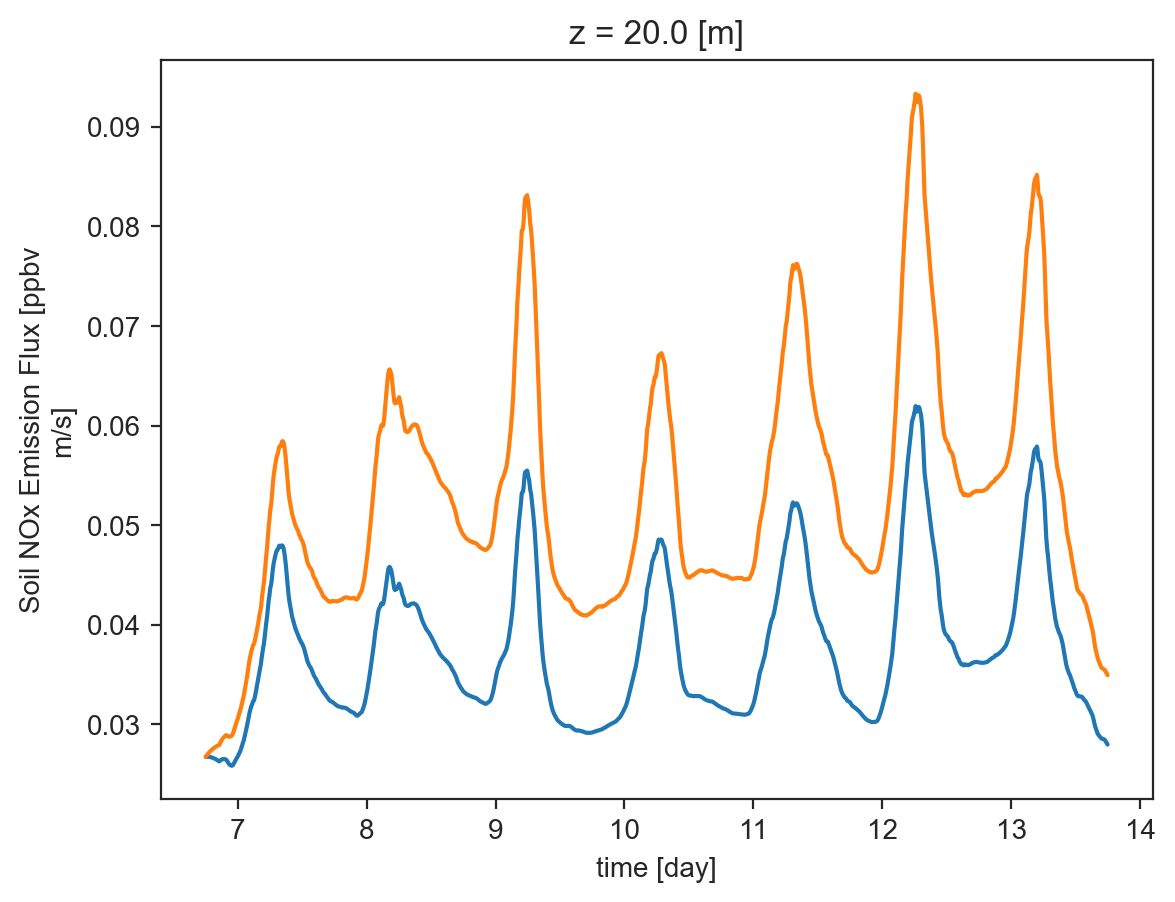

In [89]:
ds_low_var.SOILNO_E.sel(z = 20).plot()
ds_high_var.SOILNO_E.sel(z = 20).plot()

In [28]:
df_high_var_200 = pd.read_csv("Data/high_soil_NOx_high_variability_200_spectra.csv")
df_high_var_488 = pd.read_csv("Data/high_soil_NOx_high_variability_488_spectra.csv")

<Axes: >

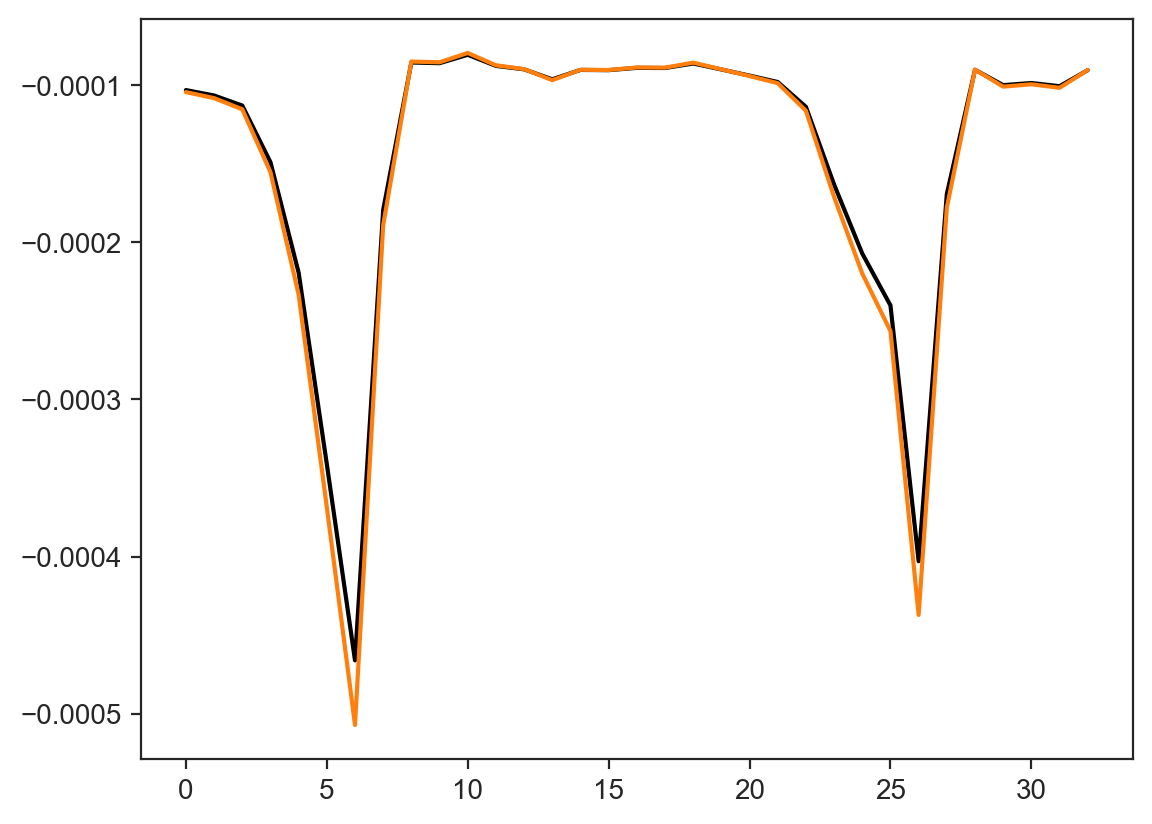

In [88]:
fig, ax = plt.subplots()
(df_200['control'] - df_200['experimental']).plot(x = df_200.wavenumbers, ax = ax, color = 'black')
(df_488['control'] - df_488['experimental'] + 0.00001).plot(x = df_488.wavenumbers, ax = ax, color = 'tab:orange')

# |ax.set_title("Low Soil $\\mathrm{NO_x}$ Variability", weight = "bold")

<Axes: >

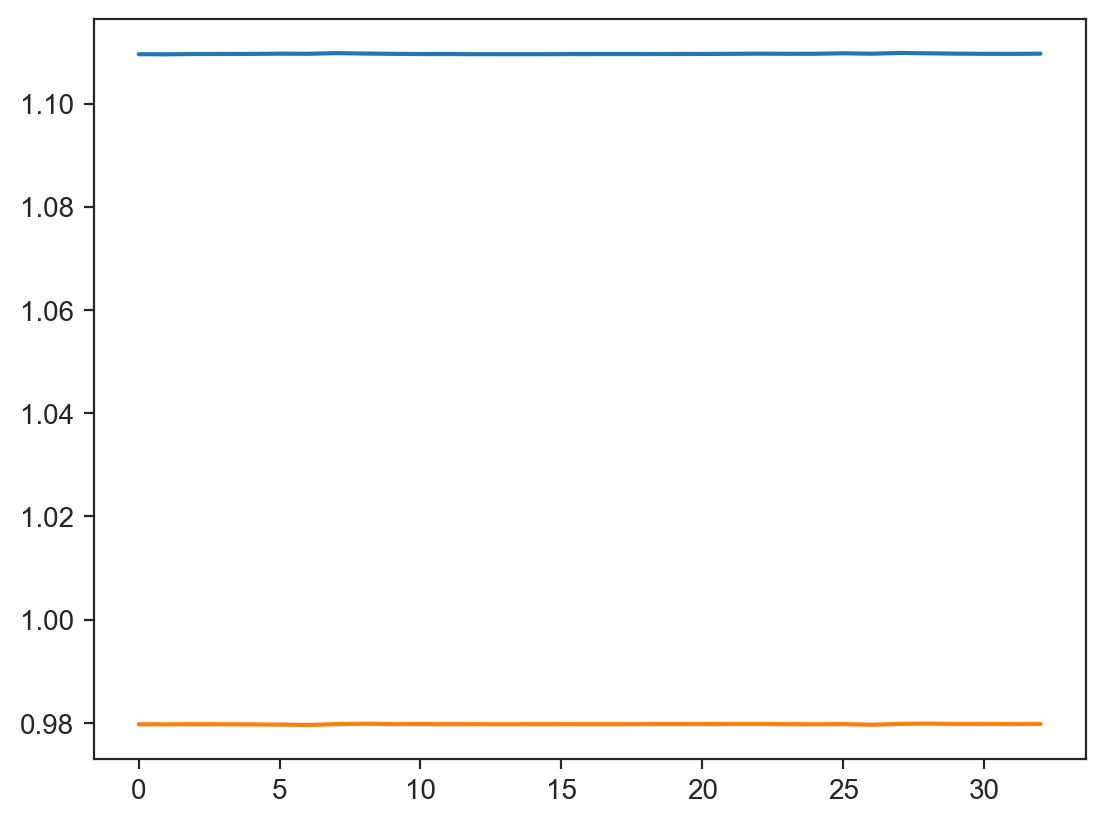

In [81]:
((df_488['control'] - df_488['experimental']) / (df_200['control'] - df_200['experimental'])).plot()
((df_high_var_488['control'] - df_high_var_488['experimental']) / (df_high_var_200['control'] - df_high_var_200['experimental'])).plot()

<Axes: >

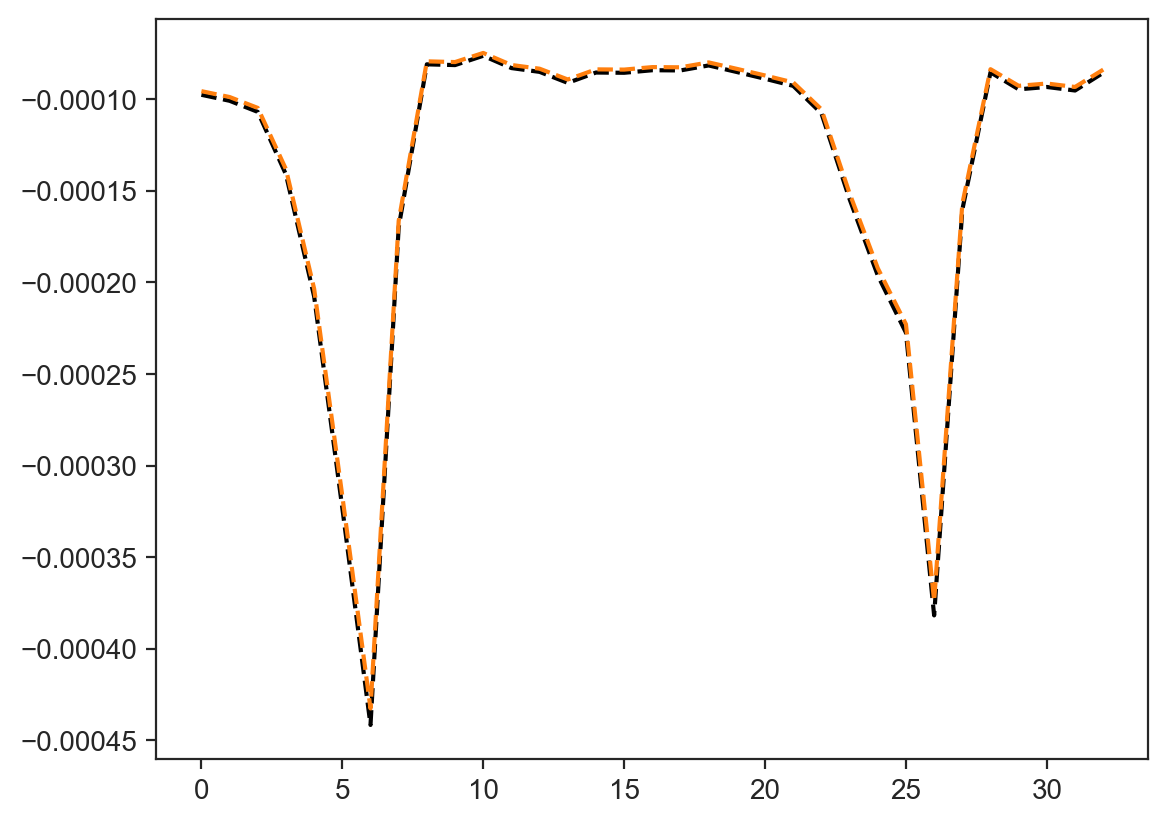

In [77]:
fig, ax = plt.subplots()

(df_high_var_200['control'] - df_high_var_200['experimental']).plot(x = df_high_var_200.wavenumbers, ax = ax, color = 'black', ls = 'dashed')
(df_high_var_488['control'] - df_high_var_488['experimental']).plot(x = df_high_var_488.wavenumbers, ax = ax, color = 'tab:orange', ls = 'dashed')


(0.0, 13000.0)

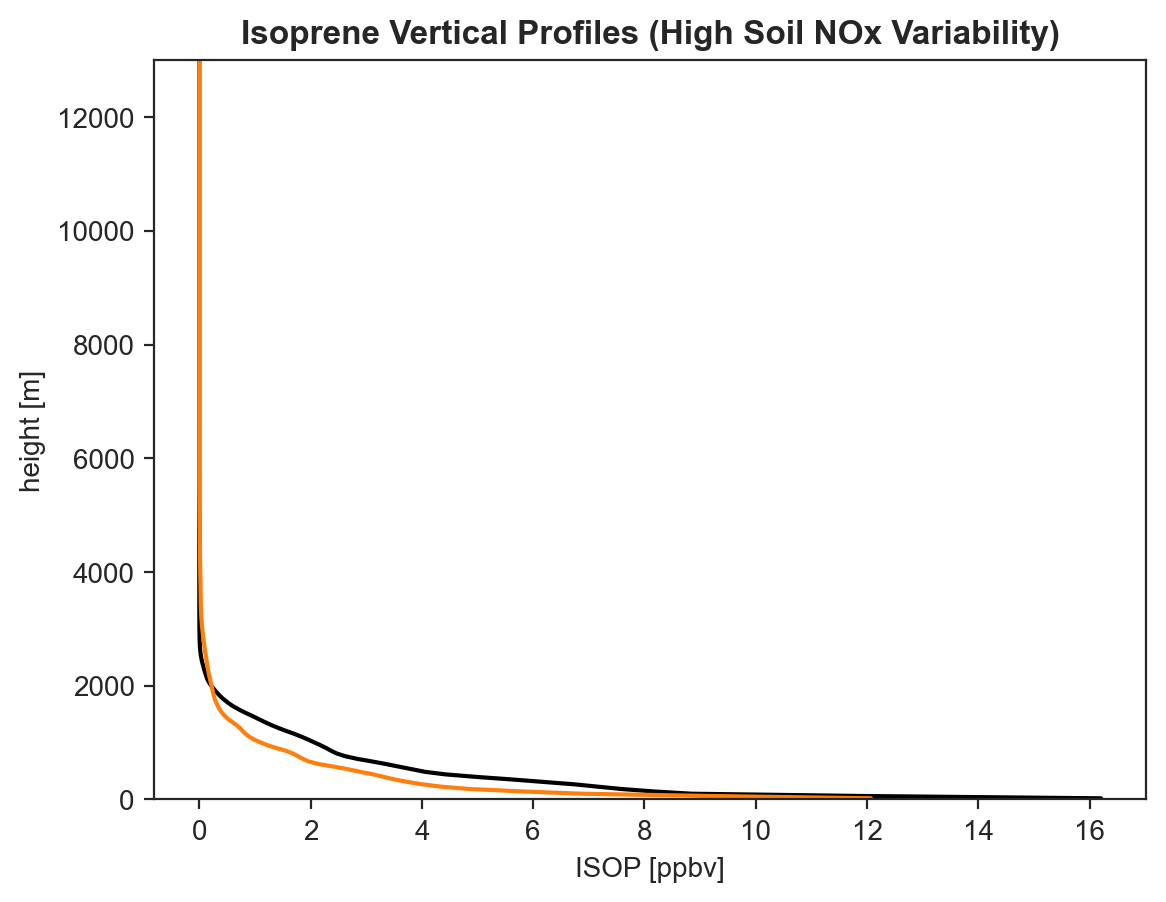

In [82]:
ds_high_var.ISOP.sel(time = ds_high_var.time[200]).plot(y = 'z', color = 'black')
ds_high_var.ISOP.sel(time = ds_high_var.time[488]).plot(y = 'z', color = 'tab:orange')
plt.title("Isoprene Vertical Profiles (High Soil NOx Variability)", weight = "bold")
plt.ylim([0, 13000])

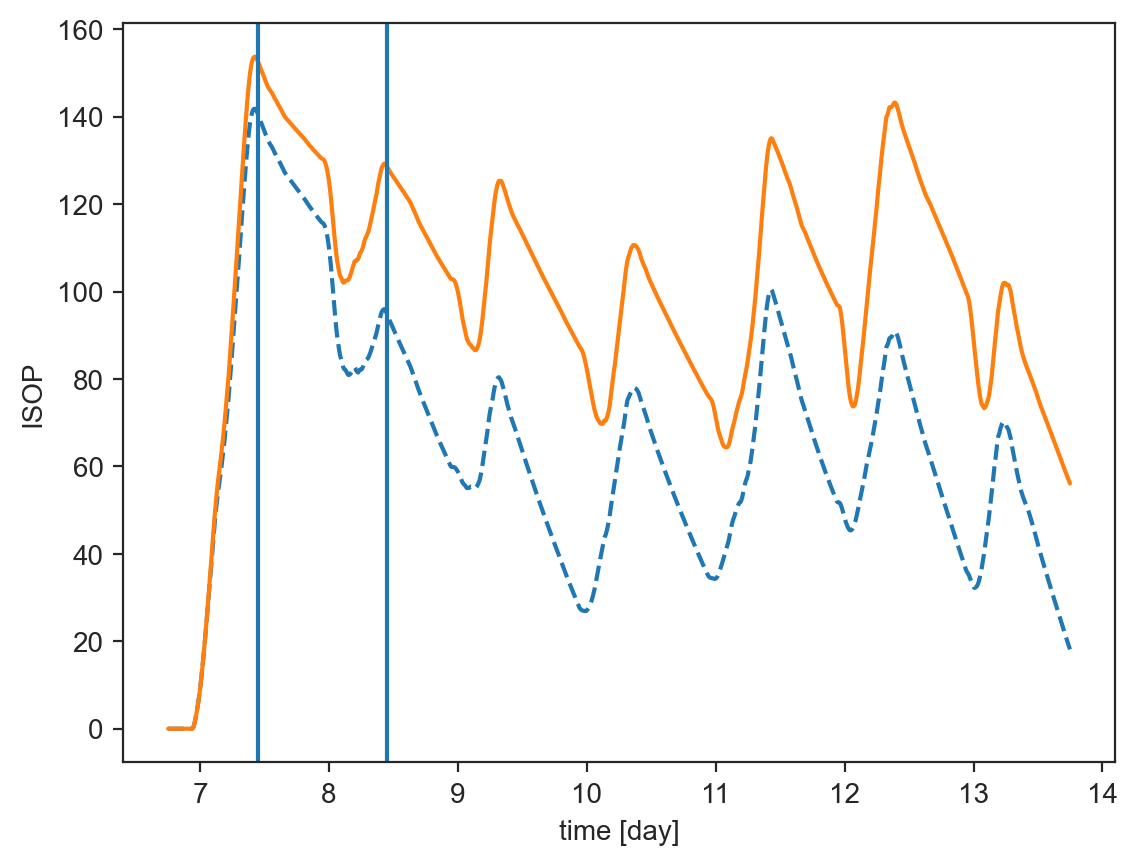

In [56]:
fig, ax = plt.subplots()
ds_high_var.ISOP.sum('z').plot( ls = 'dashed')
ds_low_var.ISOP.sum('z').plot()
ax.axvline(ds_low_var.time[200])
ax.axvline(ds_low_var.time[488])

In [106]:
ds_high_var.ISOP.sel(time = ds_low_var.time[200]).where(ds_low_var.z > 500).mean('z')


<xarray.DataArray 'ISOP' ()> Size: 4B
array(0.2002973, dtype=float32)
Coordinates:
    time     float32 4B 7.446

In [105]:
ds_low_var.ISOP.sel(time = ds_low_var.time[200]).where(ds_low_var.z > 500).mean('z')

<xarray.DataArray 'ISOP' ()> Size: 4B
array(0.22283152, dtype=float32)
Coordinates:
    time     float32 4B 7.446

(0.0, 13000.0)

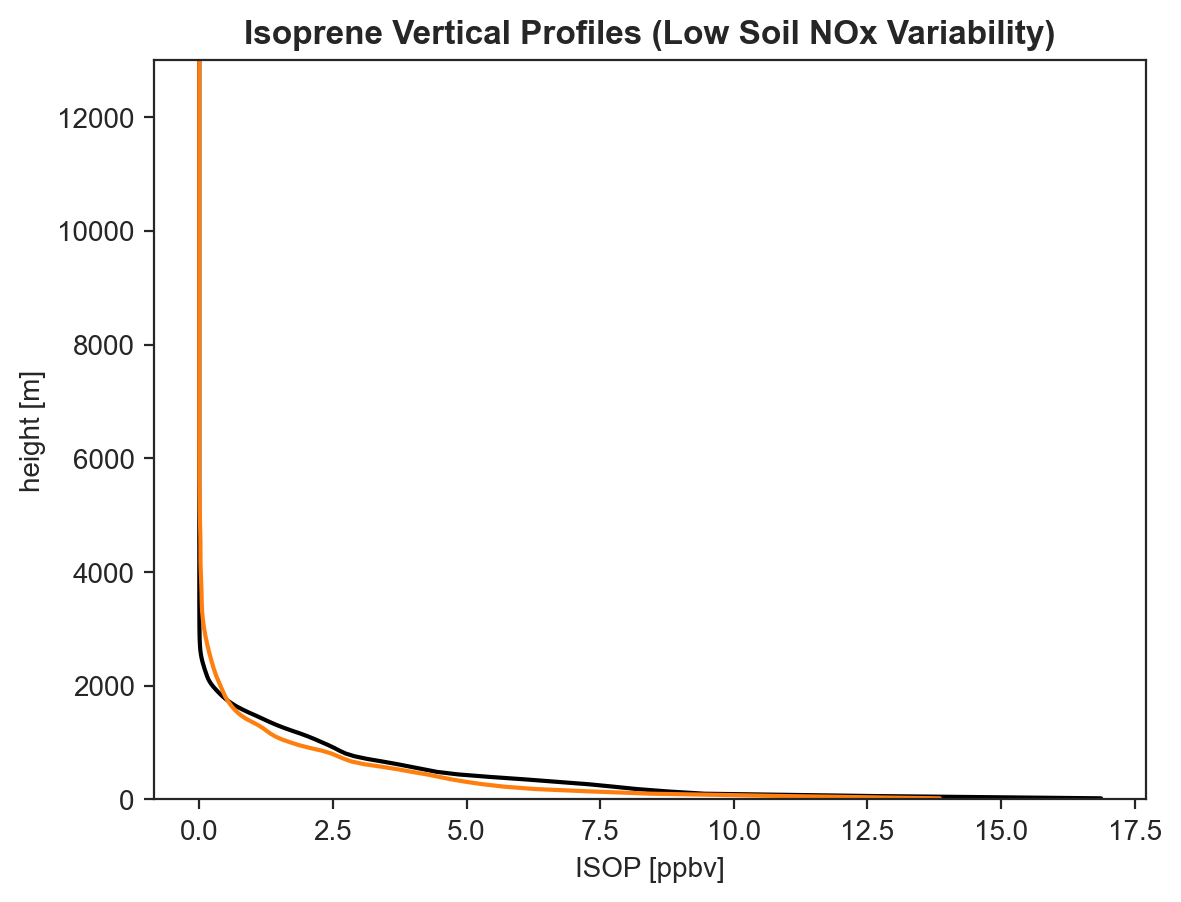

In [47]:
ds_low_var.ISOP.sel(time = ds_low_var.time[200]).plot(y = 'z', color = 'black')
ds_low_var.ISOP.sel(time = ds_low_var.time[488]).plot(y = 'z', color = 'tab:orange')
plt.title("Isoprene Vertical Profiles (Low Soil NOx Variability)", weight = "bold")
plt.ylim([0, 13000])

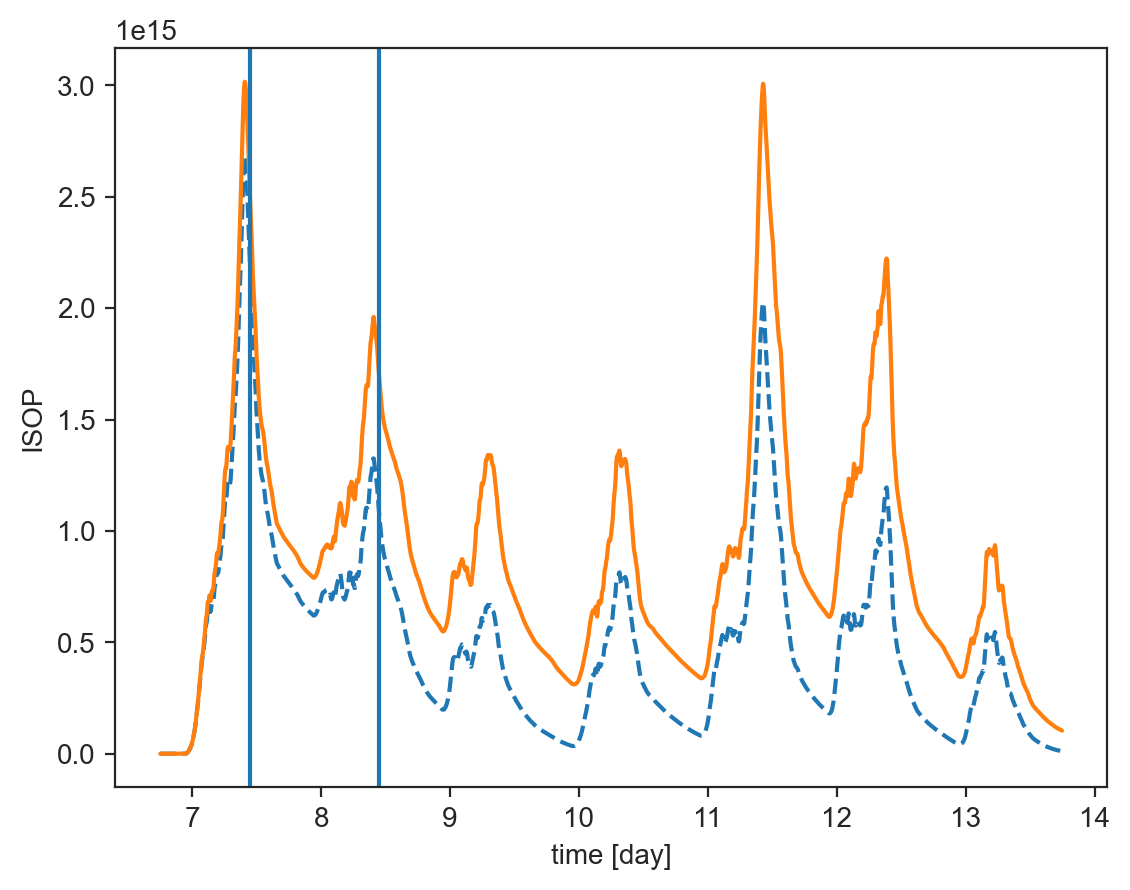

In [67]:
fig, ax = plt.subplots()
ISOP_column_high_var.ISOP.plot(ls = 'dashed')
ISOP_column.ISOP.plot()

ax.axvline(ds_low_var.time[200])
ax.axvline(ds_low_var.time[488])